# Import libraries

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
import matplotlib.pyplot as plt

In [7]:
df = pd.read_csv(r"C:\Users\bilal\Desktop\gitRepo\Locked\LockedItems\Datasets\Span_new.csv")

In [11]:
df.head

<bound method NDFrame.head of        Index      ID        make    model  months_old  power     gear  \
0          0   97860     Porsche      911         240    210   manual   
1          1   27821        Ford  Mustang          54    487   manual   
2          2   97801     Porsche      911         358    220   manual   
3          3   98251     Porsche      911          14    368   manual   
4          4   98250     Porsche      911           3    515  unknown   
...      ...     ...         ...      ...         ...    ...      ...   
92380  93986   38173        Opel    Astra         275     52   manual   
92381  93987   57303  Volkswagen     Polo         232     37   manual   
92382  93988   14541         Bmw      320         186    125   manual   
92383  93989  103604        Seat   Toledo         276     66   manual   
92384  93990   99672        Seat  Cordoba         232     81   manual   

      fuel_type     kms   price   age  
0      gasoline  202000  999999  1998  
1      gasoli

# EDA

In [9]:
df.columns

Index(['Unnamed: 0', 'ID', 'make', 'model', 'months_old', 'power', 'gear',
       'fuel_type', 'kms', 'price', 'age'],
      dtype='str')

In [10]:
df.rename({"Unnamed: 0": "Index"}, axis= 1, inplace= True)

In [14]:
df.rename({"age": "Year"}, axis = 1, inplace= True)

# IV and DV

In [22]:
dv = df["price"]
# iv = df[["power", "Year", "kms", "months_old"]]
iv = df[["power", "Year", "kms"]]

In [23]:
x_train, x_test, y_train, y_test = train_test_split(iv,dv, test_size=0.2)

In [24]:
x_train = sm.add_constant(x_train)
x_test = sm.add_constant(x_test)

In [25]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(73908, 4)
(18477, 4)
(73908,)
(18477,)


In [26]:
regressionModel2 = sm.OLS(y_train, x_train)

In [27]:
results2 = regressionModel2.fit()

In [29]:
results2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.623
Model:                            OLS   Adj. R-squared:                  0.623
Method:                 Least Squares   F-statistic:                 4.080e+04
Date:                Fri, 20 Nov 2026   Prob (F-statistic):               0.00
Time:                        23:33:58   Log-Likelihood:            -7.8220e+05
No. Observations:               73908   AIC:                         1.564e+06
Df Residuals:                   73904   BIC:                         1.564e+06
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.342e+06    2.4e+04    -55.922      0.000   -1.39e+06   -1.29e+06
power        255.8539      0.824    310.329      0.000     254.238     257.470
Year         664.3120     11.897     55.838      0.000     640.994     687.630
kms           -0.0503      0.001    -66.996      0.000      -0.052      -0.049
==============================================================================
Omnibus:                   171749.752   Durbin-Watson:                   2.000
Prob(Omnibus):                  0.000   Jarque-Bera (JB):       9216037976.616
Skew:                          22.148   Prob(JB):                         0.00
Kurtosis:                    1732.377   Cond. No.                     7.66e+07
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 7.66e+07. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

# Interpretation of OLS Regression Results (price ~ power + Year + kms)

## Summary
This multiple linear regression predicts **price** from **power**, **Year** and **kms** (mileage) on 73,908 observations. Adding mileage raised R² from 0.599 to 0.623. It also roughly **halved the Year coefficient**, showing that the earlier model gave Year credit for part of what mileage explains. All three predictors are highly significant. The residuals are still extremely non-normal, and the condition number has become much worse.

**Fitted equation:**

price = -1,342,000 + 255.85 × power + 664.31 × Year − 0.0503 × kms

---

## 1. Model information
- **Dep. Variable (price):** The outcome being predicted.
- **Model / Method (OLS / Least Squares):** Chooses the coefficients that minimise the sum of squared errors.
- **No. Observations (73,908):** Training rows used. This is 4 more than the previous model (73,904), so the two models were fitted on slightly different data.
- **Df Model (3):** Three predictors: power, Year, kms.
- **Df Residuals (73,904):** n − k − 1 = 73,908 − 3 − 1.
- **Covariance Type (nonrobust):** Standard errors assume constant error variance. This assumption is likely violated, so robust (HC3) standard errors would be more reliable.

## 2. Goodness of fit
- **R-squared = 0.623:** The model explains about 62.3% of the variance in price, up from 59.9%. Mileage adds about 2.4 percentage points of explanatory power.
- **Adj. R-squared = 0.623:** Same as R². With a large n and only 3 predictors, the penalty is negligible, so kms is a genuinely useful addition.
- **F-statistic = 40,800, Prob (F-statistic) = 0.00:** The model as a whole is highly significant. The F-value is lower than before (55,290) only because the explained variance is now spread over 3 degrees of freedom instead of 2. This does not mean the model got worse.
- **Log-Likelihood = -782,200** (previously -784,170): A higher value means better fit.
- **AIC = 1.564e6, BIC = 1.564e6** (previously 1.568e6): A drop of about 4,000 is a very large improvement. Strictly, AIC/BIC comparisons need identical data, and the sample differs by 4 rows, so treat the comparison as approximate. A gap this large is still conclusive.

## 3. Coefficients

| Term  | Coef       | Std Err | t       | P>\|t\| | 95% CI                   |
|-------|------------|---------|---------|---------|--------------------------|
| const | -1,342,000 | 24,000  | -55.92  | 0.000   | [-1,390,000, -1,290,000] |
| power | 255.85     | 0.824   | 310.33  | 0.000   | [254.24, 257.47]         |
| Year  | 664.31     | 11.897  | 55.84   | 0.000   | [640.99, 687.63]         |
| kms   | -0.0503    | 0.001   | -67.00  | 0.000   | [-0.052, -0.049]         |

- **const (-1,342,000):** The predicted price when power = 0, Year = 0 and kms = 0, which is not meaningful. It only offsets the Year term (664.31 × ~2015 ≈ 1,338,600). It is smaller than before because the Year coefficient is smaller.

- **power (255.85):** Holding Year and mileage constant, each additional unit of power increases predicted price by about 255.85 (previously 252.56). For example, 100 more units of power gives about 25,585 higher price. It is still the strongest predictor (t = 310.3) and is almost unchanged, so power is largely independent of mileage.

- **Year (664.31):** Holding power and mileage constant, each newer model year increases predicted price by about 664. That is **roughly half the previous estimate of 1,283.52**.
  - **Why it dropped:** Older cars usually have more kilometres. In the previous model, Year was absorbing both the effect of age and the effect of mileage. Now that mileage is measured separately, Year captures only the "pure age" effect: what an extra year costs a car with the same mileage.
  - This is a textbook example of **omitted variable bias** being corrected.
  - For example, a car 10 years newer with the same power and mileage is predicted to cost about 6,643 more.

- **kms (-0.0503):** Holding power and Year constant, each additional kilometre reduces predicted price by about 0.05.
  - Per 10,000 km: about 503 lower
  - Per 100,000 km: about 5,030 lower
  - The confidence interval [-0.052, -0.049] is narrow and entirely negative, so the effect is precise and clearly real.
  - t = -67.0, highly significant.

**Example prediction:** A car with power = 150, Year = 2015 and 100,000 km gives
-1,342,000 + (255.85 × 150) + (664.31 × 2015) − (0.0503 × 100,000) ≈ **30,000** (approximate, since the printed constant is rounded).

**Total depreciation of a typical car:** A car that is 10 years older and has driven 150,000 km more is predicted to be worth about 6,643 + 7,545 ≈ **14,200 less**, holding power constant. Age and mileage together still account for roughly the same total depreciation as Year did alone in the previous model.

## 4. Residual diagnostics
- **Omnibus = 171,750, Prob(Omnibus) = 0.000:** Residuals are not normal.
- **Skew = 22.15** (previously 21.47): Still extreme right skew. Some cars are priced far above prediction. Adding mileage did not help, because the outliers come from expensive brands (Porsche, Bentley, etc.), not from mileage.
- **Kurtosis = 1,732** (previously 1,637; normal = 3): Extremely heavy tails, slightly worse than before. A small number of extreme cars still dominate the residuals.
- **Jarque-Bera = 9.2 billion, Prob(JB) = 0.00:** Confirms strong non-normality.
- **Durbin-Watson = 2.000:** No autocorrelation in the residuals. This assumption is satisfied.
- **Cond. No. = 7.66e7** (previously 8.55e5): About 90 times worse. The cause is scale, not a real problem in the data:
  - kms values run into the hundreds of thousands, while the coefficient is tiny (0.05).
  - Year values (~2000) sit far from zero, so the Year column is nearly collinear with the intercept.
  - **Fix:** express mileage in thousands of km (kms / 1000) and replace Year with age (2026 − Year). The condition number would drop sharply and the coefficients would be easier to read (e.g. about −50.3 per 1,000 km).

## 5. Comparison with the previous model

| Metric          | power + Year | power + Year + kms |
|-----------------|--------------|--------------------|
| R²              | 0.599        | 0.623              |
| AIC             | 1.568e6      | 1.564e6            |
| power coef      | 252.56       | 255.85             |
| Year coef       | 1,283.52     | 664.31             |
| kms coef        | —            | -0.0503            |
| Residual skew   | 21.47        | 22.15              |
| Kurtosis        | 1,637        | 1,732              |
| Condition No.   | 8.55e5       | 7.66e7             |

**Key takeaways:**
1. Mileage is a genuinely important predictor. Fit improved and AIC dropped substantially.
2. The Year effect was overstated by about 2× in the earlier model, because it was standing in for mileage.
3. The power effect is stable, which means it is a robust estimate.
4. The outlier and non-normality problem is unchanged. Mileage does not explain the extreme prices; brand probably does.

## 6. Practical implications
1. **The coefficients are reasonable average effects**, and the Year estimate is now more trustworthy.
2. **The p-values and standard errors are not reliable as printed**, because of heteroskedasticity and non-robust covariance. Use cov_type="HC3".
3. **Statistical significance is not the same as importance.** With n ≈ 74k, every p-value is ≈ 0. Judge importance from coefficient size and changes in R².
4. **The linear form is still questionable.** Depreciation is usually a percentage per year and per km, which suggests modelling log(price).

## 7. Recommended next steps
- Add the **make** dummies (Volkswagen as baseline). This should most directly reduce the skew and kurtosis and raise R².
- Rescale: **kms_000 = kms / 1000** and **age = 2026 − Year**, to fix the condition number.
- Use robust standard errors: **.fit(cov_type="HC3")**.
- Try **log(price)** as the dependent variable.
- Inspect and possibly remove impossible or extreme rows (price ≤ 0, kms = 0 for old cars, prices in the millions).

## Conclusion
Power, model year and mileage all significantly affect price. Each unit of power adds about **256**, each newer year adds about **664**, and each 100,000 km reduces price by about **5,030**. The model now explains **62.3%** of price variation, and including mileage corrected an earlier overestimate of the age effect by about half. However, the extreme skewness (22.15), kurtosis (1,732) and very high condition number (7.66e7) show that the model still needs brand information, rescaled variables, a log-transformed price and robust standard errors before its results are relied on.

# Add the brand info 

In [40]:
df.make.value_counts()

make
Bmw              10546
Audi              9368
Volkswagen        8749
Renault           6379
Opel              6136
Ford              5839
Citroen           5689
Mercedes-Benz     5592
Peugeot           5273
Seat              4900
Toyota            3067
Fiat              2830
Nissan            2764
Hyundai           2013
Volvo             1958
Land              1523
Porsche           1416
Kia               1185
Skoda             1052
Honda              802
Jeep               690
Smart              682
Mazda              611
Alfa               402
Mitsubishi         394
Chevrolet          389
Ds                 348
Mini               317
Jaguar             278
Ssangyong          269
Chrysler           236
Dacia              196
Saab               156
Bentley            117
Suzuki             110
Iveco              109
Name: count, dtype: int64

In [46]:
# Before encoding check for null
df.tail()

,Index,ID,make,model,months_old,power,gear,fuel_type,kms,price,Year
92380,93986,38173,Opel,Astra,275,52,manual,gasoline,134700,350,1995
92381,93987,57303,Volkswagen,Polo,232,37,manual,gasoline,67762,350,1998
92382,93988,14541,Bmw,320,186,125,manual,gasoline,200000,300,2002
92383,93989,103604,Seat,Toledo,276,66,manual,gasoline,196000,300,1995
92384,93990,99672,Seat,Cordoba,232,81,manual,diesel,150000,200,1998


In [42]:
print(df["make"].isna().sum())                       # value_counts hides missing values
print(df["make"].value_counts(dropna=False).sum(), len(df))   # these two should match

0
92385 92385


In [43]:
df[df["make"].isin(["Porsche", "Bentley", "Mercedes-Benz"])].nlargest(10, "price")[["make", "power", "Year", "kms", "price"]]

,make,power,Year,kms,price
0,Porsche,210,1998,202000,999999
2,Porsche,220,1988,56300,555555
3,Porsche,368,2016,2800,470000
4,Porsche,515,2017,10,450000
5,Porsche,368,2016,145,445000
6,Bentley,522,2017,3500,399000
7,Mercedes-Benz,115,2015,29000,330000
8,Bentley,522,2017,1200,302900
9,Bentley,522,2016,17900,289700
10,Bentley,522,2017,9900,284900


In [44]:
# Create summy variables 

In [79]:
df["make"] = df["make"].replace({"Land": "Land Rover", "Alfa": "Alfa Romeo"})


makes = ["Volkswagen"] + sorted(m for m in df["make"].unique() if m != "Volkswagen") # Sorting with Volkswagon
df["make"] = pd.Categorical(df["make"], categories=makes)


In [50]:
df.head()

,Index,ID,make,model,months_old,power,gear,fuel_type,kms,price,Year
0,0,97860,Porsche,911,240,210,manual,gasoline,202000,999999,1998
1,1,27821,Ford,Mustang,54,487,manual,gasoline,30000,685000,2013
2,2,97801,Porsche,911,358,220,manual,gasoline,56300,555555,1988
3,3,98251,Porsche,911,14,368,manual,gasoline,2800,470000,2016
4,4,98250,Porsche,911,3,515,unknown,gasoline,10,450000,2017


In [51]:
make_dummies = pd.get_dummies(df["make"], prefix="make", drop_first=True, dtype=float)

X = pd.concat([df[["power", "Year", "kms"]], make_dummies], axis=1)
y = df["price"]

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
x_train = sm.add_constant(x_train, has_constant="add")
x_test  = sm.add_constant(x_test,  has_constant="add")
print(x_train.shape, x_test.shape)   # should be (73908, 39) and (18477, 39)

results = sm.OLS(y_train, x_train).fit()
print(results.summary())
y_pred = results.predict(x_test)

(73908, 39) (18477, 39)
                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.659
Model:                            OLS   Adj. R-squared:                  0.658
Method:                 Least Squares   F-statistic:                     3751.
Date:                Fri, 20 Nov 2026   Prob (F-statistic):               0.00
Time:                        23:49:56   Log-Likelihood:            -7.8044e+05
No. Observations:               73908   AIC:                         1.561e+06
Df Residuals:                   73869   BIC:                         1.561e+06
Df Model:                          38                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const       

In [52]:
y_pred = results.predict(x_test)

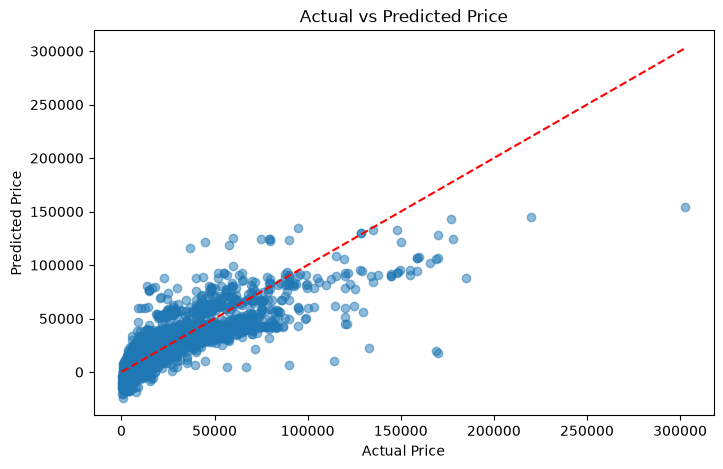

In [53]:
import seaborn as sns

plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)


Text(0.5, 1.0, 'Residual Plot')

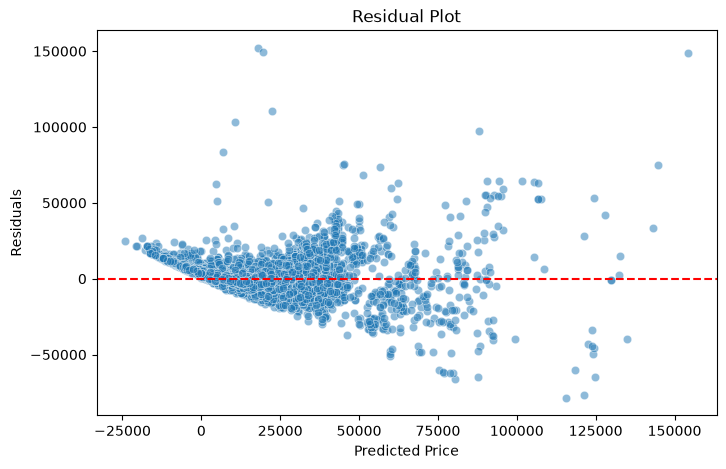

In [54]:
residuals = y_test - y_pred

plt.figure(figsize=(8,5))

sns.scatterplot(x=y_pred, y=residuals, alpha=0.5)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")


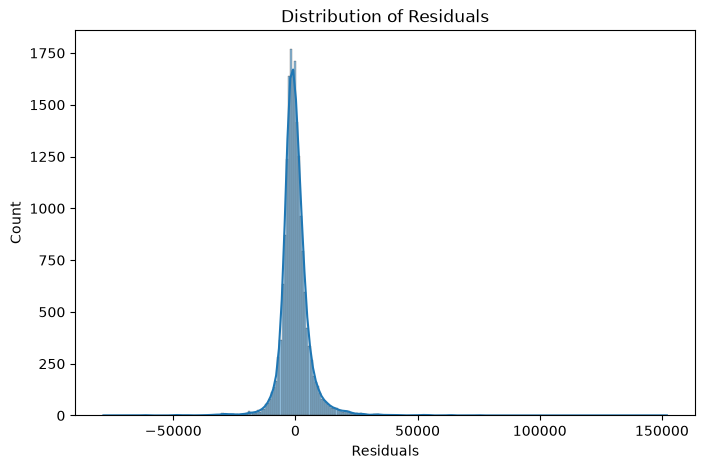

In [55]:
plt.figure(figsize=(8,5))

sns.histplot(residuals, kde=True)

plt.xlabel("Residuals")
plt.title("Distribution of Residuals")

plt.show()

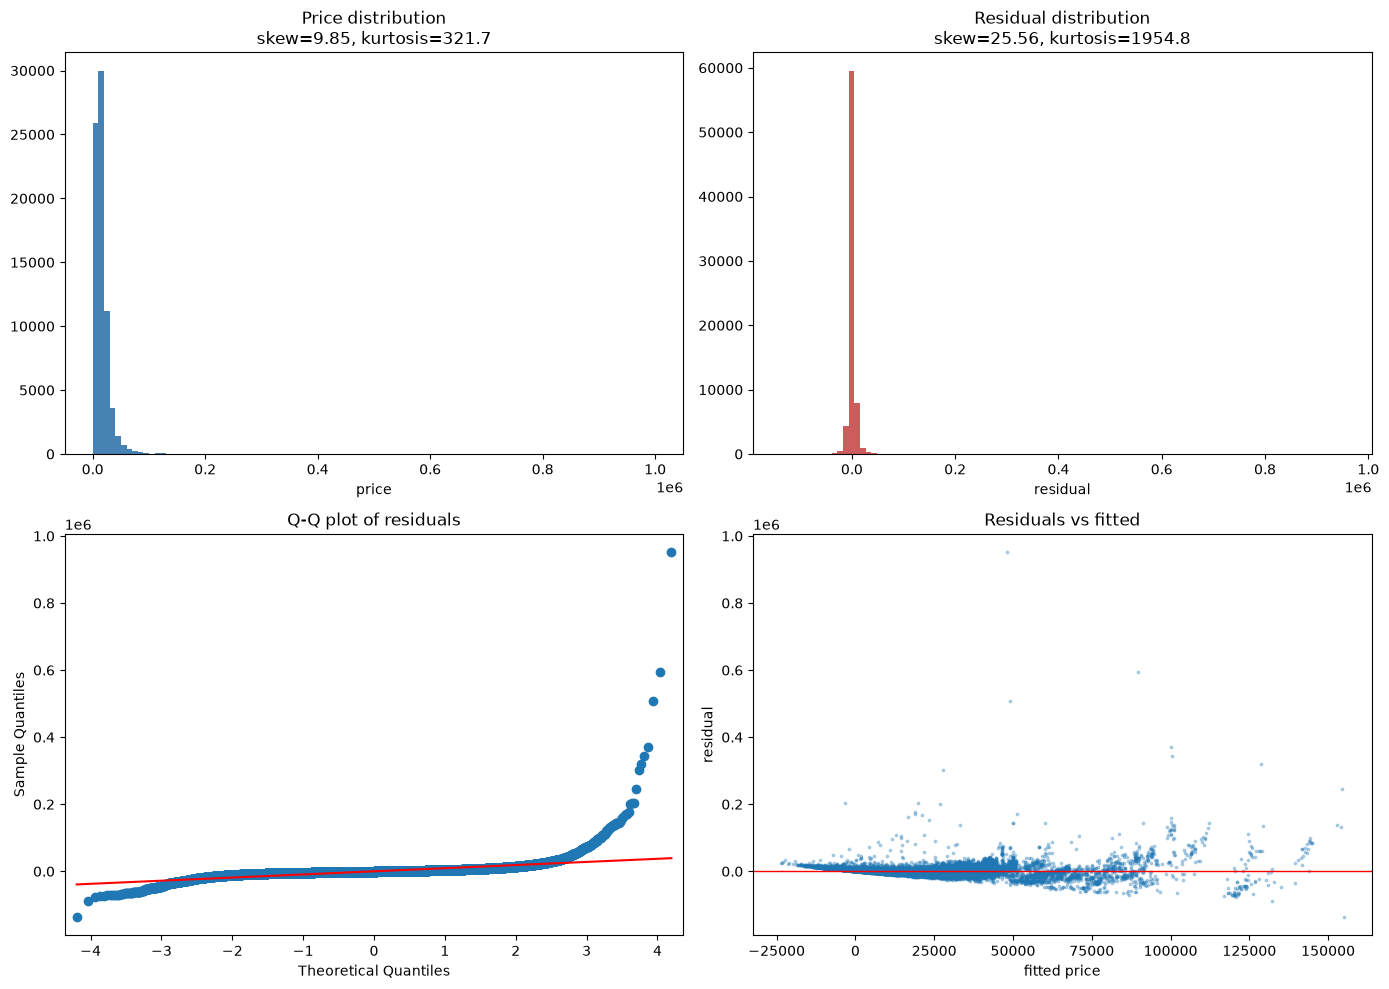

In [56]:
from scipy.stats import skew, kurtosis

resid  = results.resid
fitted = results.fittedvalues

fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# 1. Distribution of price
ax[0, 0].hist(y_train, bins=100, color="steelblue")
ax[0, 0].set_title(f"Price distribution\nskew={skew(y_train):.2f}, "
                   f"kurtosis={kurtosis(y_train, fisher=False):.1f}")
ax[0, 0].set_xlabel("price")

# 2. Distribution of residuals
ax[0, 1].hist(resid, bins=100, color="indianred")
ax[0, 1].set_title(f"Residual distribution\nskew={skew(resid):.2f}, "
                   f"kurtosis={kurtosis(resid, fisher=False):.1f}")
ax[0, 1].set_xlabel("residual")

# 3. Q-Q plot of residuals
sm.qqplot(resid, line="s", ax=ax[1, 0])
ax[1, 0].set_title("Q-Q plot of residuals")

# 4. Residuals vs fitted
ax[1, 1].scatter(fitted, resid, s=3, alpha=0.3)
ax[1, 1].axhline(0, color="red", lw=1)
ax[1, 1].set_title("Residuals vs fitted")
ax[1, 1].set_xlabel("fitted price")
ax[1, 1].set_ylabel("residual")

plt.tight_layout()
plt.show()

# 4th iteration

In [57]:
# Include all the catagorical variables

In [58]:
df.columns

Index(['Index', 'ID', 'make', 'model', 'months_old', 'power', 'gear',
       'fuel_type', 'kms', 'price', 'Year'],
      dtype='str')

In [61]:
print(df.make.value_counts())

make
Bmw              10546
Audi              9368
Volkswagen        8749
Renault           6379
Opel              6136
Ford              5839
Citroen           5689
Mercedes-Benz     5592
Peugeot           5273
Seat              4900
Toyota            3067
Fiat              2830
Nissan            2764
Hyundai           2013
Volvo             1958
Land Rover        1523
Porsche           1416
Kia               1185
Skoda             1052
Honda              802
Jeep               690
Smart              682
Mazda              611
Alfa Romeo         402
Mitsubishi         394
Chevrolet          389
Ds                 348
Mini               317
Jaguar             278
Ssangyong          269
Chrysler           236
Dacia              196
Saab               156
Bentley            117
Suzuki             110
Iveco              109
Name: count, dtype: int64


In [66]:
print(df.model.index)

RangeIndex(start=0, stop=92385, step=1)


In [76]:
df.gear.value_counts()

gear
manual            66584
automatic         24275
unknown            1234
semi-automatic      292
Name: count, dtype: int64

In [74]:
models = df['model'].unique().tolist()
print(models)

['911', 'Mustang', 'Continental', 'Cla200', 'RoverRangeRover', '118', 'A3', 'Cayenne', 'Kangoo', 'Panamera', 'E220', 'Viano', 'X3', 'Sportage', 'A5', '320', 'A7', 'A4', 'RoverRangeRoverSport', 'Macan', 'A6', 'Touareg', 'Tt', 'A8', 'Asx', '308', 'GrandC4Picasso', 'RoverDefender', 'X5', 'X6', '508', '640', 'RoverDiscovery', 'X1', '730', 'Leon', '120', 'Passat', 'Xc90', 'GrandCherokee', 'Montero', 'Q7', '330', 'Ml350', '530', 'B200', 'Corsa', 'Clio', 'Wrangler', 'Xc60', 'E350', 'LandCruiser', 'Boxster', 'Cls350', 'X4', 'GrandVoyager', 'Ducato', 'V220', 'Q5', '520', 'RoverRangeRoverEvoque', 'Xf', '220', 'Focus', 'Z4', 'Q3', 'Pulsar', 'C220', '207', 'T5Multivan', '420', 'Xe', 'V60', 'Sprinter', 'A4Allroad', 'Transporter', 'C200', 'Vito', 'Golf', 'Q2', 'Tiguan', 'GolfGti', 'Beetle', '218', 'Espace', 'Cla220', '318', 'Touran', 'Insignia', 'Sharan', 'Fiesta', 'X-Trail', 'Spacetourer', 'Slk200', 'PassatVariant', 'Trafic', '325', 'SantaFe', 'Civic', 'C4Picasso', 'Gla200', 'Mondeo', 'Compass', 'O

In [77]:
df.fuel_type.value_counts()

fuel_type
diesel      70699
gasoline    21028
hybrid        470
electric       92
unknown        53
LPG            43
Name: count, dtype: int64

In [78]:

# Baseline (reference) category for each column
baselines = {
    "make": "Volkswagen",
    "gear": "manual",
    "fuel_type": "diesel",
}

dummies = []
for col, base in baselines.items():
    order = [base] + sorted(c for c in df[col].unique() if c != base)   # baseline first
    df[col] = pd.Categorical(df[col], categories=order)
    dummies.append(pd.get_dummies(df[col], prefix=col, drop_first=True, dtype=float))

X = pd.concat([df[["power", "Year", "kms"]]] + dummies, axis=1)
y = df["price"]

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
x_train = sm.add_constant(x_train, has_constant="add")
x_test  = sm.add_constant(x_test,  has_constant="add")
print(x_train.shape, x_test.shape)   # 47 columns: const + 3 numeric + 35 make + 3 gear + 5 fuel

results = sm.OLS(y_train, x_train).fit()
print(results.summary())
y_pred = results.predict(x_test)

(73908, 47) (18477, 47)
                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.664
Model:                            OLS   Adj. R-squared:                  0.664
Method:                 Least Squares   F-statistic:                     3180.
Date:                Sat, 21 Nov 2026   Prob (F-statistic):               0.00
Time:                        00:38:20   Log-Likelihood:            -7.7981e+05
No. Observations:               73908   AIC:                         1.560e+06
Df Residuals:                   73861   BIC:                         1.560e+06
Df Model:                          46                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const     